# Exploratory Data Analysis (EDA) Project
# Phase 2 — K-Means Clustering

**Name:** ANINDO PRITOM BARUA  
**Registration Number:** 23BDS0328  
**Course:** Exploratory Data Analysis (EDA)  
**Dataset:** Indian Food Dataset

## Objective

The objective of this notebook is to apply K-Means clustering to the Indian Food dataset to group recipes with similar preparation and cooking characteristics.

The numerical variables preparation time, cooking time, and total time will be standardized before clustering. The Elbow Method and Silhouette Score will be used to determine an appropriate number of clusters. The resulting clusters will then be visualized and interpreted using two-dimensional and three-dimensional plots.

PHASE 2 - K-MEANS CLUSTERING

Dataset loaded successfully.
Rows    : 255
Columns : 20

FEATURES USED FOR CLUSTERING
['prep_time', 'cook_time', 'total_time']

Number of observations: 255

STANDARDIZED DATA


,prep_time,cook_time,total_time
0,-0.222420,-0.094028,-0.222914
1,-0.291469,0.217363,-0.114888
2,-0.291469,0.321160,-0.060876
3,-0.291469,0.321160,-0.060876
4,-0.222420,0.840146,0.263201
5,0.191876,-0.197825,0.047150
6,-0.360519,0.009769,-0.276927
7,-0.291469,0.009769,-0.222914
8,-0.153371,0.528754,0.155176
9,0.675221,-0.094028,0.479253



ELBOW METHOD


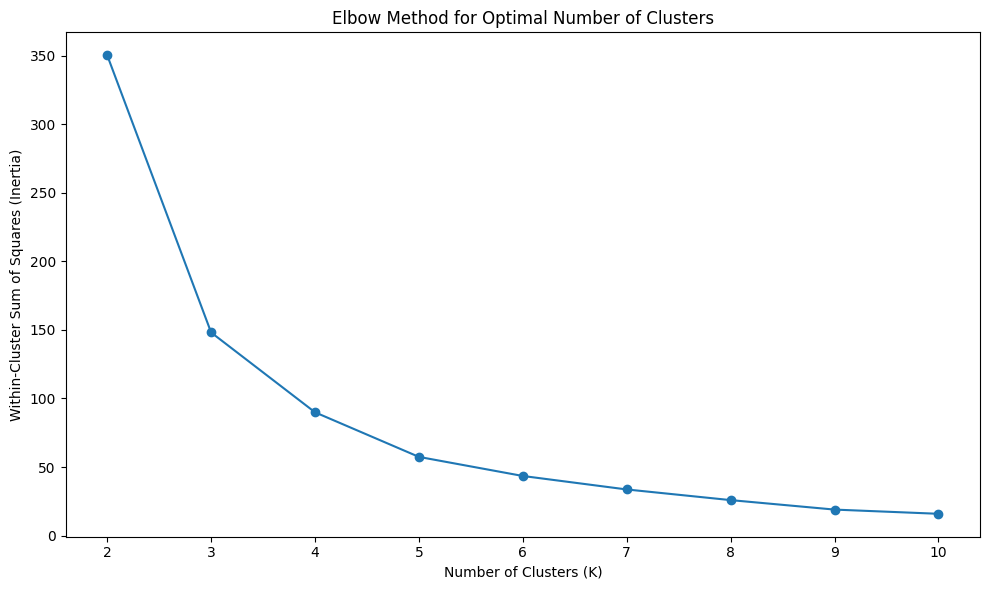


SILHOUETTE SCORE ANALYSIS


,Number of Clusters,Silhouette Score
0,2,0.859660
1,3,0.853472
2,4,0.769005
3,5,0.449838
4,6,0.507790
5,7,0.479392
6,8,0.515356
7,9,0.521110
8,10,0.482278


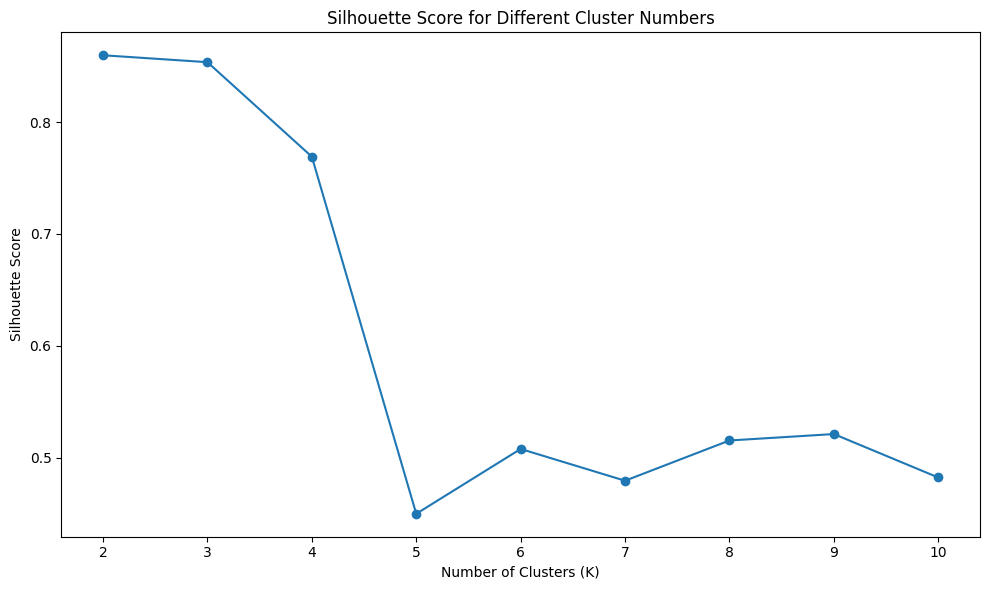


OPTIMAL NUMBER OF CLUSTERS
Best K based on highest Silhouette Score: 2

CLUSTER SIZES


,Number of Recipes
Cluster,
0,242
1,13



CLUSTER CENTERS - STANDARDIZED SCALE


,prep_time,cook_time,total_time
Cluster,,,
0,-0.198624,-0.087165,-0.200729
1,3.697457,1.622616,3.736642



CLUSTER CENTERS - ORIGINAL SCALE


,prep_time,cook_time,total_time
Cluster,,,
0,16.72,30.33,47.05
1,298.85,112.69,411.54


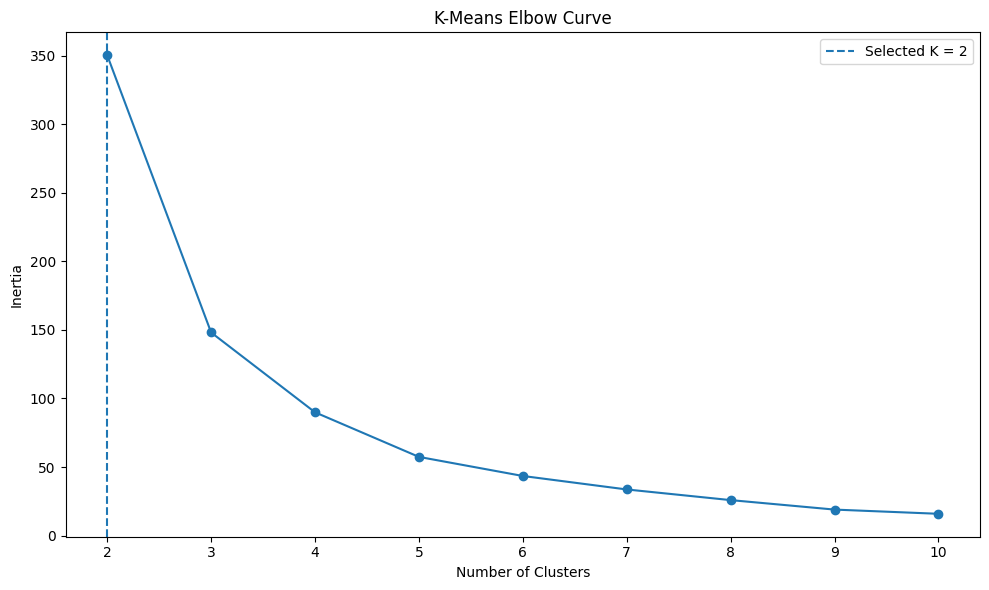

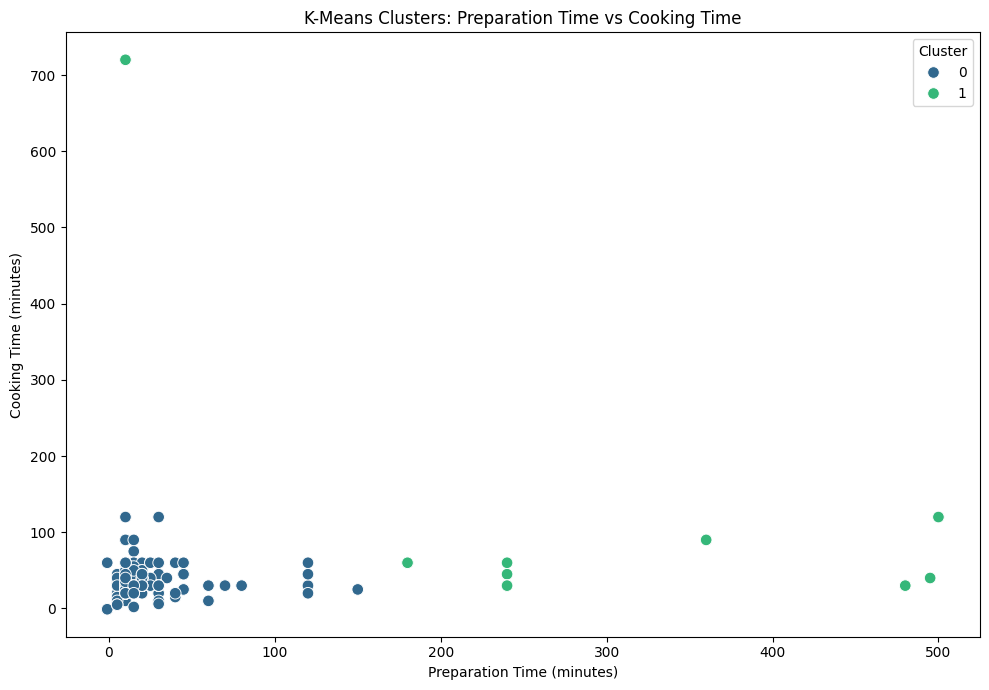

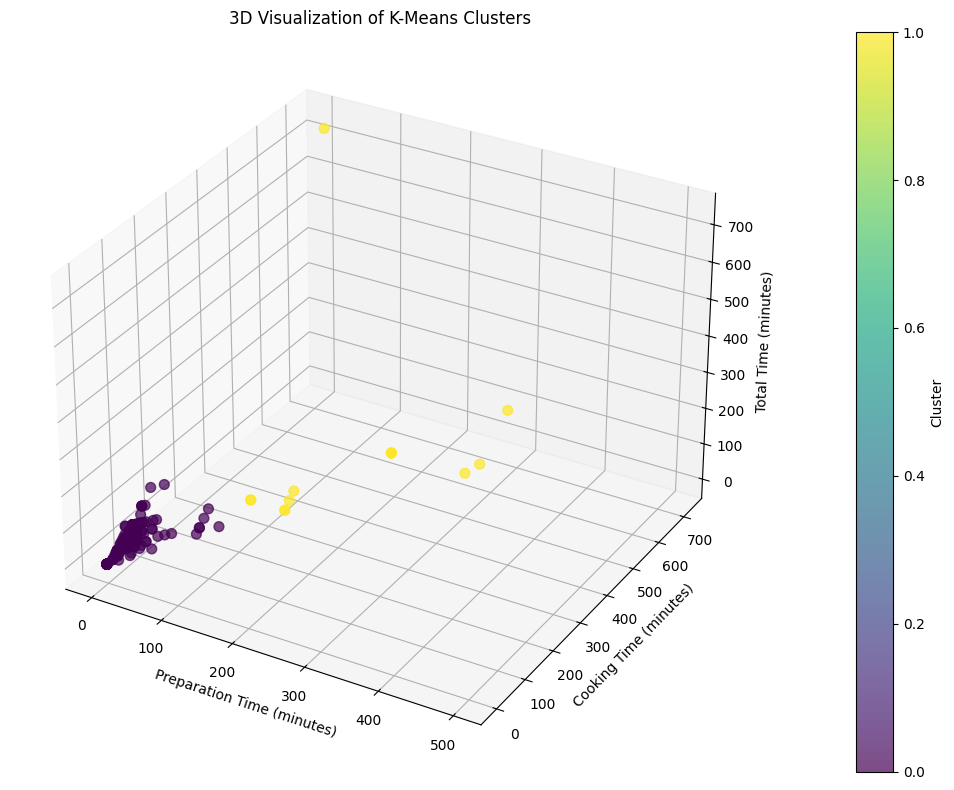


CLUSTER PROFILE


,prep_time,cook_time,total_time
Cluster,,,
0,16.72,30.33,47.05
1,298.85,112.69,411.54



FINAL CLUSTER PROFILE


,prep_time,cook_time,total_time,Recipe_Count
Cluster,,,,
0,16.72,30.33,47.05,242
1,298.85,112.69,411.54,13



K-MEANS CLUSTERING COMPLETED
Clustered dataset saved as: indian_food_kmeans_clustered.csv


In [1]:
# ============================================================
# PHASE 2 - K-MEANS CLUSTERING
# Name        : ANINDO PRITOM BARUA
# Registration: 23BDS0328
# Dataset     : Indian Food Dataset
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

from mpl_toolkits.mplot3d import Axes3D

# ------------------------------------------------------------
# 1. Load the transformed dataset
# ------------------------------------------------------------

file_path = "indian_food_transformed.csv"

df = pd.read_csv(file_path)

print("=" * 75)
print("PHASE 2 - K-MEANS CLUSTERING")
print("=" * 75)

print("\nDataset loaded successfully.")
print("Rows    :", df.shape[0])
print("Columns :", df.shape[1])

# ------------------------------------------------------------
# 2. Select clustering variables
# ------------------------------------------------------------

features = [
    "prep_time",
    "cook_time",
    "total_time"
]

clustering_data = df[features].copy()

# Remove rows with missing values
clustering_data = clustering_data.dropna()

print("\nFEATURES USED FOR CLUSTERING")
print("=" * 75)
print(features)

print("\nNumber of observations:", len(clustering_data))

# ------------------------------------------------------------
# 3. Standardize the numerical variables
# ------------------------------------------------------------

scaler = StandardScaler()

X_scaled = scaler.fit_transform(
    clustering_data
)

X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=features
)

print("\nSTANDARDIZED DATA")
print("=" * 75)

display(X_scaled_df.head(10))

# ------------------------------------------------------------
# 4. Elbow Method
# ------------------------------------------------------------

print("\nELBOW METHOD")
print("=" * 75)

inertia_values = []

K_range = range(2, 11)

for k in K_range:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    inertia_values.append(
        kmeans.inertia_
    )

# Plot Elbow Curve

plt.figure(figsize=(10, 6))

plt.plot(
    list(K_range),
    inertia_values,
    marker="o"
)

plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Within-Cluster Sum of Squares (Inertia)")
plt.xticks(list(K_range))
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 5. Silhouette Score Analysis
# ------------------------------------------------------------

print("\nSILHOUETTE SCORE ANALYSIS")
print("=" * 75)

silhouette_scores = []

for k in K_range:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(
        X_scaled
    )

    score = silhouette_score(
        X_scaled,
        labels
    )

    silhouette_scores.append(score)

silhouette_table = pd.DataFrame({
    "Number of Clusters": list(K_range),
    "Silhouette Score": silhouette_scores
})

display(silhouette_table)

# Plot Silhouette Scores

plt.figure(figsize=(10, 6))

plt.plot(
    list(K_range),
    silhouette_scores,
    marker="o"
)

plt.title("Silhouette Score for Different Cluster Numbers")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(list(K_range))
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. Select optimal K
# ------------------------------------------------------------

best_k = list(K_range)[
    np.argmax(silhouette_scores)
]

print("\nOPTIMAL NUMBER OF CLUSTERS")
print("=" * 75)

print(
    "Best K based on highest Silhouette Score:",
    best_k
)

# ------------------------------------------------------------
# 7. Apply Final K-Means Model
# ------------------------------------------------------------

final_kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

cluster_labels = final_kmeans.fit_predict(
    X_scaled
)

clustering_data["Cluster"] = cluster_labels

# ------------------------------------------------------------
# 8. Cluster Sizes
# ------------------------------------------------------------

print("\nCLUSTER SIZES")
print("=" * 75)

cluster_sizes = (
    clustering_data["Cluster"]
    .value_counts()
    .sort_index()
)

display(
    cluster_sizes.to_frame(
        name="Number of Recipes"
    )
)

# ------------------------------------------------------------
# 9. Cluster Centers
# ------------------------------------------------------------

print("\nCLUSTER CENTERS - STANDARDIZED SCALE")
print("=" * 75)

cluster_centers_scaled = pd.DataFrame(
    final_kmeans.cluster_centers_,
    columns=features
)

cluster_centers_scaled.index.name = "Cluster"

display(
    cluster_centers_scaled
)

# Convert cluster centers back to original scale

cluster_centers_original = pd.DataFrame(
    scaler.inverse_transform(
        final_kmeans.cluster_centers_
    ),
    columns=features
)

cluster_centers_original.index.name = "Cluster"

print("\nCLUSTER CENTERS - ORIGINAL SCALE")
print("=" * 75)

display(
    cluster_centers_original.round(2)
)

# ------------------------------------------------------------
# 10. Merge cluster labels with original dataset
# ------------------------------------------------------------

df_clustered = df.loc[
    clustering_data.index
].copy()

df_clustered["Cluster"] = cluster_labels

# ------------------------------------------------------------
# 11. Visualization 1
# Elbow Curve
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    list(K_range),
    inertia_values,
    marker="o"
)

plt.axvline(
    best_k,
    linestyle="--",
    label=f"Selected K = {best_k}"
)

plt.title("K-Means Elbow Curve")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 12. Visualization 2
# 2D Cluster Visualization
# ------------------------------------------------------------

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=clustering_data,
    x="prep_time",
    y="cook_time",
    hue="Cluster",
    palette="viridis",
    s=70
)

plt.title(
    "K-Means Clusters: Preparation Time vs Cooking Time"
)

plt.xlabel("Preparation Time (minutes)")
plt.ylabel("Cooking Time (minutes)")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 13. Visualization 3
# 3D Cluster Visualization
# ------------------------------------------------------------

fig = plt.figure(figsize=(11, 8))

ax = fig.add_subplot(
    111,
    projection="3d"
)

scatter = ax.scatter(
    clustering_data["prep_time"],
    clustering_data["cook_time"],
    clustering_data["total_time"],
    c=clustering_data["Cluster"],
    cmap="viridis",
    s=50,
    alpha=0.7
)

ax.set_title(
    "3D Visualization of K-Means Clusters"
)

ax.set_xlabel(
    "Preparation Time (minutes)"
)

ax.set_ylabel(
    "Cooking Time (minutes)"
)

ax.set_zlabel(
    "Total Time (minutes)"
)

plt.colorbar(
    scatter,
    ax=ax,
    pad=0.1,
    label="Cluster"
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 14. Cluster Profile
# ------------------------------------------------------------

print("\nCLUSTER PROFILE")
print("=" * 75)

cluster_profile = (
    df_clustered
    .groupby("Cluster")[features]
    .mean()
    .round(2)
)

display(cluster_profile)

# ------------------------------------------------------------
# 15. Cluster Profile Including Recipe Count
# ------------------------------------------------------------

cluster_profile["Recipe_Count"] = (
    df_clustered
    .groupby("Cluster")
    .size()
)

print("\nFINAL CLUSTER PROFILE")
print("=" * 75)

display(cluster_profile)

# ------------------------------------------------------------
# 16. Save clustered dataset
# ------------------------------------------------------------

output_file = "indian_food_kmeans_clustered.csv"

df_clustered.to_csv(
    output_file,
    index=False
)

print("\n" + "=" * 75)
print("K-MEANS CLUSTERING COMPLETED")
print("=" * 75)

print(
    "Clustered dataset saved as:",
    output_file
)

## Conclusion

K-Means clustering was successfully applied to the Indian Food dataset using preparation time, cooking time, and total time as clustering features.

The numerical variables were standardized before clustering to ensure that differences in scale did not disproportionately affect the distance calculations. The Elbow Method and Silhouette Score were used to evaluate different numbers of clusters and select an appropriate clustering configuration.

The final K-Means model assigned each recipe to a cluster and provided cluster centers that describe the characteristics of each group. Two-dimensional and three-dimensional visualizations were used to examine the separation and distribution of the clusters.

A cluster profile was also generated to compare the average preparation, cooking, and total times of each cluster. The clustered dataset was saved as `indian_food_kmeans_clustered.csv`.

The analysis demonstrates how unsupervised machine learning can be used to group recipes according to their preparation and cooking characteristics.